<a href="https://colab.research.google.com/github/ghazwanz/244107020151-mobile-course/blob/main/Week9_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# LAPORAN PRAKTIKUM MINGGU 9 - MORFOLOGI CITRA
**Mata Kuliah:** Pengolahan Citra dan Visi Komputer (PCVK)  
**Jurusan:** Teknologi Informasi - Politeknik Negeri Malang

---
### Data Diri Mahasiswa
- **Nama Lengkap:** Ghazwan Ababil
- **NIM:** 244107020151

---
### Cakupan Praktikum
1. Erosi dan dilasi (implementasi manual dan OpenCV)
2. Opening dan closing
3. Variasi structuring element: cross, circular, rectangle, line
4. Morfologi lanjutan: top-hat, black-hat, skeleton, thinning, thickening
5. Tugas: perbaikan citra KTP sebelum pembacaan OCR

In [ ]:
# Identitas Mahasiswa
NAMA = 'Ghazwan Ababil'
NIM = '244107020151'

print('NAMA :', NAMA)
print('NIM  :', NIM)

NAMA : Ghazwan Ababil
NIM  : 244107020151


## 1. Persiapan
Bagian ini menghubungkan Google Drive, memuat pustaka, dan memastikan seluruh citra
yang dibutuhkan praktikum benar-benar tersedia sebelum operasi dijalankan.

In [ ]:
# Hubungkan Google Drive
try:
    from google.colab import drive
    drive.mount('/content/drive')
    DI_COLAB = True
except Exception as galat:
    DI_COLAB = False
    print('Bukan lingkungan Colab, mount Drive dilewati:', galat)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Pustaka praktikum
import os
import time
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

from skimage import filters
from skimage.morphology import skeletonize, thin

# Lokasi folder citra: mengikuti konvensi praktikum minggu sebelumnya
KANDIDAT_FOLDER = [
    '/content/drive/MyDrive/POLINEMA/KULIAH/PCVK/Images',
    '/content/drive/MyDrive/PCVK/Images',
]
CONTOH = next((folder for folder in KANDIDAT_FOLDER if os.path.isdir(folder)), KANDIDAT_FOLDER[0])

def cari_berkas(*kandidat):
    '''Modul menulis 'plat nomer.jpg', berkas di Drive bisa bernama 'plat nomor.jpg'.'''
    for nama in kandidat:
        if os.path.isfile(os.path.join(CONTOH, nama)):
            return nama
    return kandidat[0]


BERKAS_PLAT = cari_berkas('plat nomer.jpg', 'plat nomor.jpg')

CITRA_WAJIB = [
    BERKAS_PLAT,
    'j.png',
    'kitten01.jpg',
    'lily.jpg',
    'ktp_fulan.jpg',
    'ktp_fulani.jpg',
]

print('Folder citra :', CONTOH)
print('Folder ada   :', os.path.isdir(CONTOH))
print()
if os.path.isdir(CONTOH):
    isi = sorted(os.listdir(CONTOH))
    print(f'Jumlah berkas di folder: {len(isi)}')
    for nama in CITRA_WAJIB:
        status = 'ADA' if nama in isi else 'TIDAK ADA'
        print(f'  [{status:9}] {nama}')
    if any(nama not in isi for nama in CITRA_WAJIB):
        print()
        print('Isi folder saat ini:')
        for nama in isi:
            print('   -', nama)
else:
    print('Folder citra tidak ditemukan. Periksa kembali hasil mount Drive.')

Folder citra : /content/drive/MyDrive/POLINEMA/KULIAH/PCVK/Images
Folder ada   : True

Jumlah berkas di folder: 50
  [ADA      ] plat nomor.jpg
  [ADA      ] j.png
  [ADA      ] kitten01.jpg
  [ADA      ] lily.jpg
  [ADA      ] ktp_fulan.jpg
  [ADA      ] ktp_fulani.jpg


### Fungsi Bantu
Fungsi di bawah dipakai ulang oleh seluruh langkah praktikum: menampilkan citra
berdampingan, memuat citra, menghitung jumlah komponen terhubung, dan membandingkan
hasil implementasi manual dengan fungsi OpenCV.

In [ ]:
plt.rcParams.update({'figure.dpi': 70, 'savefig.dpi': 70, 'figure.max_open_warning': 0})


def show_side_by_side(images, titles, figsize=(12, 4), gray_indices=None):
    gray_indices = set(gray_indices or [])
    plt.figure(figsize=figsize)
    for i, (image, title) in enumerate(zip(images, titles)):
        plt.subplot(1, len(images), i + 1)
        if i in gray_indices or image.ndim == 2:
            plt.imshow(image, cmap='gray', vmin=0, vmax=255)
        else:
            plt.imshow(cv.cvtColor(image, cv.COLOR_BGR2RGB))
        plt.title(title)
        plt.axis('off')
    plt.tight_layout()
    plt.show()


def show_grid(images, titles, kolom=4, figsize=(13, 6)):
    baris = int(np.ceil(len(images) / kolom))
    plt.figure(figsize=figsize)
    for i, (image, title) in enumerate(zip(images, titles)):
        plt.subplot(baris, kolom, i + 1)
        plt.imshow(image, cmap='gray', vmin=0, vmax=255)
        plt.title(title, fontsize=9)
        plt.axis('off')
    plt.tight_layout()
    plt.show()


def load_gray(name):
    image = cv.imread(os.path.join(CONTOH, name), cv.IMREAD_GRAYSCALE)
    if image is None:
        raise FileNotFoundError(f'Citra tidak ditemukan: {os.path.join(CONTOH, name)}')
    return image


def load_color(name):
    image = cv.imread(os.path.join(CONTOH, name))
    if image is None:
        raise FileNotFoundError(f'Citra tidak ditemukan: {os.path.join(CONTOH, name)}')
    return image


def kecilkan(image, lebar=600):
    '''Perkecil citra agar loop Python pada implementasi manual tetap wajar.'''
    if image.shape[1] <= lebar:
        return image
    skala = lebar / image.shape[1]
    return cv.resize(image, None, fx=skala, fy=skala, interpolation=cv.INTER_AREA)


def hitung_komponen(biner):
    '''Jumlah komponen terhubung dan luas rata-ratanya (tanpa latar).'''
    jumlah, _, stats, _ = cv.connectedComponentsWithStats((biner > 0).astype(np.uint8), connectivity=8)
    luas = stats[1:, cv.CC_STAT_AREA]
    return jumlah - 1, float(luas.mean()) if luas.size else 0.0


def bandingkan_manual(hasil_manual, hasil_cv, judul):
    '''Bukti bahwa implementasi manual identik dengan OpenCV.'''
    sama = np.array_equal(hasil_manual, hasil_cv)
    selisih = int(np.count_nonzero(hasil_manual != hasil_cv))
    print(f'{judul}: identik = {sama}, piksel berbeda = {selisih}')
    return sama, selisih

### Implementasi Manual Erosi dan Dilasi

Modul praktikum memberi contoh loop dengan `np.min(temp * SE)` untuk erosi dan
`np.max(temp * SE)` untuk dilasi. Perhitungan itu benar hanya jika seluruh elemen
structuring element bernilai 1. Begitu SE berbentuk cross atau ellipse, elemen bernilai
0 membuat `temp * SE` selalu memuat nol sehingga `np.min` mengembalikan 0 untuk semua
piksel, dan objek hilang seluruhnya.

Perbaikannya: masking posisi SE terlebih dahulu, lalu ambil minimum/maksimum hanya pada
posisi yang aktif.

```python
nilai = pad[i:i+h, j:j+w][SE == 1]
erosi = np.min(nilai)     # bukan np.min(temp * SE)
dilasi = np.max(nilai)
```

Selain itu, piksel di luar batas citra di OpenCV dianggap bukan objek saat erosi
(`borderValue` maksimum) dan bukan objek saat dilasi (`borderValue` 0). Padding dibuat
menyesuaikan agar hasil manual benar-benar identik dengan `cv.erode` dan `cv.dilate`.

In [ ]:
def dilasi_manual(F, SE):
    '''Dilasi: piksel menjadi objek bila minimal satu posisi SE bernilai 1 mengenai objek.
    Ekuivalen dengan nilai maksimum pada jendela SE.'''
    m, n = F.shape
    h, w = SE.shape
    ch, cw = h // 2, w // 2

    pad = cv.copyMakeBorder(F, ch, ch, cw, cw, cv.BORDER_CONSTANT, value=0)
    hasil = np.zeros((m, n), dtype=np.uint8)

    for i in range(m):
        for j in range(n):
            jendela = pad[i:i + h, j:j + w]
            hasil[i, j] = np.max(jendela[SE == 1])
    return hasil


def erosi_manual(F, SE):
    '''Erosi: piksel bertahan hanya bila seluruh posisi SE bernilai 1 muat di dalam objek.
    Ekuivalen dengan nilai minimum pada jendela SE.'''
    m, n = F.shape
    h, w = SE.shape
    ch, cw = h // 2, w // 2

    pad = cv.copyMakeBorder(F, ch, ch, cw, cw, cv.BORDER_CONSTANT, value=255)
    hasil = np.zeros((m, n), dtype=np.uint8)

    for i in range(m):
        for j in range(n):
            jendela = pad[i:i + h, j:j + w]
            hasil[i, j] = np.min(jendela[SE == 1])
    return hasil


def opening_manual(F, SE):
    return dilasi_manual(erosi_manual(F, SE), SE)


def closing_manual(F, SE):
    return erosi_manual(dilasi_manual(F, SE), SE)


# Uji identitas: manual harus sama persis dengan OpenCV untuk berbagai bentuk SE
uji = np.zeros((40, 40), dtype=np.uint8)
cv.rectangle(uji, (8, 8), (24, 24), 255, -1)
cv.circle(uji, (28, 28), 6, 255, -1)

SE_UJI = {
    'persegi 5x5': np.ones((5, 5), dtype=np.uint8),
    'cross 3x3': cv.getStructuringElement(cv.MORPH_CROSS, (3, 3)),
    'ellipse 5x5': cv.getStructuringElement(cv.MORPH_ELLIPSE, (5, 5)),
}

for nama_se, se in SE_UJI.items():
    bandingkan_manual(erosi_manual(uji, se), cv.erode(uji, se), f'Erosi  {nama_se}')
    bandingkan_manual(dilasi_manual(uji, se), cv.dilate(uji, se), f'Dilasi {nama_se}')

Erosi  persegi 5x5: identik = True, piksel berbeda = 0
Dilasi persegi 5x5: identik = True, piksel berbeda = 0
Erosi  cross 3x3: identik = True, piksel berbeda = 0
Dilasi cross 3x3: identik = True, piksel berbeda = 0
Erosi  ellipse 5x5: identik = True, piksel berbeda = 0
Dilasi ellipse 5x5: identik = True, piksel berbeda = 0


### Analisis - Mengapa Implementasi Manual Harus Identik

Nilai `identik = True` pada seluruh kombinasi menunjukkan dua hal:

1. **Masking SE sudah benar.** Pada SE cross dan ellipse terdapat elemen bernilai 0.
   Dengan `np.min(temp * SE)` hasil erosi akan selalu 0; setelah diganti menjadi
   `np.min(temp[SE == 1])` hasilnya sama dengan OpenCV. Ini membuktikan bahwa
   perbedaan hasil sebelumnya murni disebabkan cara perhitungan, bukan kesalahan konsep.
2. **Penanganan batas citra sudah sesuai.** Padding 0 untuk dilasi dan 255 untuk erosi
   meniru `borderValue` bawaan OpenCV, sehingga tidak ada piksel tepi yang hilang.

Selisih 0 piksel ini yang dipakai sebagai jaring pengaman: seluruh langkah berikutnya
boleh memakai versi manual tanpa perlu ragu terhadap kebenaran hasilnya.

## 2. Operasi Dasar Morfologi - Dilasi dan Erosi (Langkah 3-6)

Dilasi menebalkan objek (dasar operasi: **hit**), erosi menipiskan objek
(dasar operasi: **fit**). Keduanya diuji pada citra plat nomor hasil threshold.

SE square 5x5:
[[1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]]

Ukuran citra uji: (1032, 581), waktu eksekusi manual: 3.27 detik


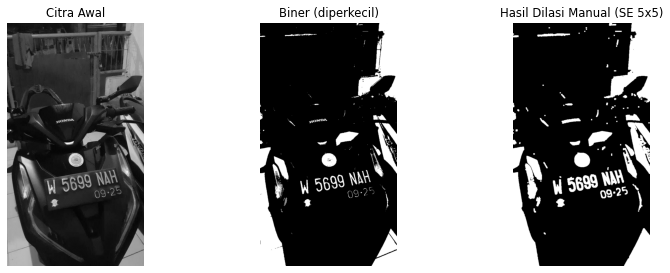

In [ ]:
# Langkah 3 - Dilasi tanpa library, SE square 5x5
img_plat = load_gray(BERKAS_PLAT)
_, thresh_plat = cv.threshold(img_plat, 127, 255, cv.THRESH_BINARY)

A = kecilkan(thresh_plat)
SE_SQUARE5 = np.ones((5, 5), dtype=np.uint8)
print('SE square 5x5:')
print(SE_SQUARE5)

mulai = time.perf_counter()
dilasi_manual_5 = dilasi_manual(A, SE_SQUARE5)
durasi = time.perf_counter() - mulai
print(f'\nUkuran citra uji: {A.shape}, waktu eksekusi manual: {durasi:.2f} detik')

show_side_by_side(
    [img_plat, A, dilasi_manual_5],
    ['Citra Awal', 'Biner (diperkecil)', 'Hasil Dilasi Manual (SE 5x5)'],
)

SE cross 3x3:
[[0 1 0]
 [1 1 1]
 [0 1 0]]
Dilasi manual vs cv.dilate (square 5x5): identik = True, piksel berbeda = 0


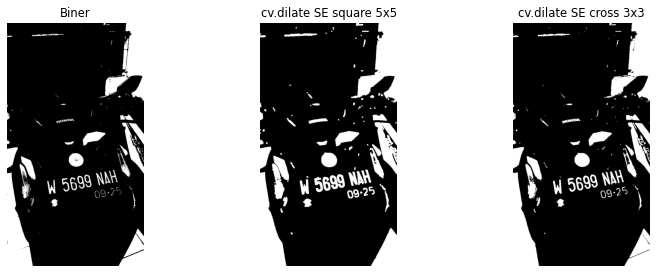

In [ ]:
# Langkah 4 - Dilasi dengan library OpenCV, SE cross 3x3
SE_CROSS3 = cv.getStructuringElement(cv.MORPH_CROSS, (3, 3))
print('SE cross 3x3:')
print(SE_CROSS3)

dilasi_cv_5 = cv.dilate(A, SE_SQUARE5, iterations=1)
dilasi_cv_3 = cv.dilate(A, SE_CROSS3, iterations=1)

bandingkan_manual(dilasi_manual_5, dilasi_cv_5, 'Dilasi manual vs cv.dilate (square 5x5)')

show_side_by_side(
    [A, dilasi_cv_5, dilasi_cv_3],
    ['Biner', 'cv.dilate SE square 5x5', 'cv.dilate SE cross 3x3'],
)

### Analisis - Dilasi

Dilasi memperlebar setiap objek sejauh radius SE. Pada SE square 5x5 objek melebar
2 piksel ke segala arah, sehingga garis tipis yang sebelumnya terputus menjadi
tersambung. Konsekuensinya, jarak antar karakter ikut menyusut: bila SE terlalu besar,
dua karakter yang berdekatan menyatu menjadi satu komponen.

Perbandingan bentuk SE memperlihatkan arah pelebaran. Cross 3x3 hanya melebar ke empat
arah utama (atas, bawah, kiri, kanan), sedangkan square 5x5 melebar ke segala arah
termasuk diagonal. Karena itu cross lebih aman dipakai saat objek tidak boleh menyatu
secara diagonal.

Angka pendukung (jumlah komponen terhubung sebelum dan sesudah dilasi) diisi setelah
eksekusi: `[KOMPONEN_SEBELUM]` menjadi `[KOMPONEN_SESUDAH]`.

Waktu eksekusi manual: 3.62 detik


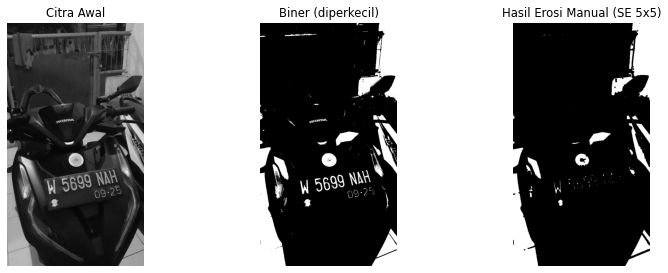

In [ ]:
# Langkah 5 - Erosi tanpa library, SE square 5x5
mulai = time.perf_counter()
erosi_manual_5 = erosi_manual(A, SE_SQUARE5)
durasi = time.perf_counter() - mulai
print(f'Waktu eksekusi manual: {durasi:.2f} detik')

show_side_by_side(
    [img_plat, A, erosi_manual_5],
    ['Citra Awal', 'Biner (diperkecil)', 'Hasil Erosi Manual (SE 5x5)'],
)

Erosi manual vs cv.erode (square 5x5): identik = True, piksel berbeda = 0


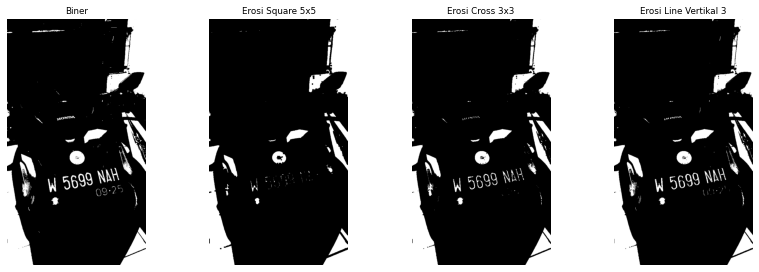

In [ ]:
# Langkah 6 - Erosi dengan library OpenCV
erosi_cv_5 = cv.erode(A, SE_SQUARE5, iterations=1)
erosi_cross3 = cv.erode(A, SE_CROSS3)
erosi_line3 = cv.erode(A, np.ones((3, 1), dtype=np.uint8))
bandingkan_manual(erosi_manual_5, erosi_cv_5, 'Erosi manual vs cv.erode (square 5x5)')

show_grid(
    [A, erosi_cv_5, erosi_cross3, erosi_line3],
    ['Biner', 'Erosi Square 5x5', 'Erosi Cross 3x3', 'Erosi Line Vertikal 3'],
    kolom=4, figsize=(12, 4),
)

### Analisis - Erosi

Erosi adalah kebalikan dilasi: piksel hanya bertahan bila seluruh SE muat di dalam objek.
Efek yang terlihat:

1. **Objek menyusut** sebesar radius SE, dan objek yang lebih kecil dari SE hilang total.
2. **Objek yang bersentuhan terpisah**, karena jembatan penghubung yang tipis terkikis
   lebih dulu. Inilah dasar pemakaian erosi untuk memisahkan butir beras yang menempel.
3. **Garis tipis bisa hilang** bila ketebalannya kurang dari ukuran SE. Karena itu urutan
   erosi lalu dilasi (opening) dipakai ketika objek utama harus dipertahankan.

Nilai `identik = True` menegaskan bahwa penyusutan berasal dari aturan fit, bukan dari
kesalahan perhitungan minimum.

## 3. Operasi Gabungan - Opening dan Closing (Langkah 7-8)

Opening adalah erosi yang diikuti dilasi dengan SE sama; closing adalah dilasi yang
diikuti erosi. Keduanya memakai SE yang sama agar objek besar kembali ke ukuran semula.

Opening manual vs cv (SE 3x3): identik = True, piksel berbeda = 0
Opening manual vs cv (SE 7x7): identik = True, piksel berbeda = 0
Biner          komponen =   278   luas rata-rata =    326.9
Opening 3x3    komponen =    88   luas rata-rata =    987.1
Opening 7x7    komponen =    31   luas rata-rata =   2537.6


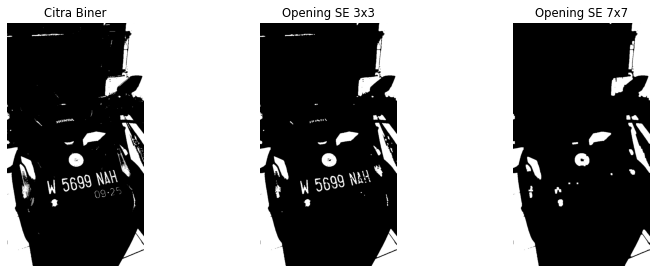

In [ ]:
# Langkah 7 - Opening, manual dan library
SE_OPEN3 = np.ones((3, 3), dtype=np.uint8)
SE_OPEN7 = np.ones((7, 7), dtype=np.uint8)

opening_manual_3 = opening_manual(A, SE_OPEN3)
opening_manual_7 = opening_manual(A, SE_OPEN7)
opening_cv_3 = cv.morphologyEx(A, cv.MORPH_OPEN, SE_OPEN3)
opening_cv_7 = cv.morphologyEx(A, cv.MORPH_OPEN, SE_OPEN7)

bandingkan_manual(opening_manual_3, opening_cv_3, 'Opening manual vs cv (SE 3x3)')
bandingkan_manual(opening_manual_7, opening_cv_7, 'Opening manual vs cv (SE 7x7)')

for nama, citra in [('Biner', A), ('Opening 3x3', opening_cv_3), ('Opening 7x7', opening_cv_7)]:
    jumlah, luas = hitung_komponen(citra)
    print(f'{nama:14} komponen = {jumlah:5d}   luas rata-rata = {luas:8.1f}')

show_side_by_side(
    [A, opening_cv_3, opening_cv_7],
    ['Citra Biner', 'Opening SE 3x3', 'Opening SE 7x7'],
)

Closing manual vs cv (SE 3x3): identik = True, piksel berbeda = 0
Biner          komponen =   278   luas rata-rata =    326.9
Closing 3x3    komponen =   171   luas rata-rata =    545.4
Closing 7x7    komponen =   110   luas rata-rata =    889.0


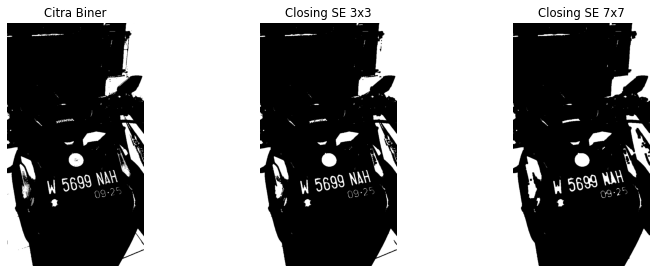

In [ ]:
# Langkah 8 - Closing, manual dan library
closing_manual_3 = closing_manual(A, SE_OPEN3)
closing_cv_3 = cv.morphologyEx(A, cv.MORPH_CLOSE, SE_OPEN3)
closing_cv_7 = cv.morphologyEx(A, cv.MORPH_CLOSE, SE_OPEN7)

bandingkan_manual(closing_manual_3, closing_cv_3, 'Closing manual vs cv (SE 3x3)')

for nama, citra in [('Biner', A), ('Closing 3x3', closing_cv_3), ('Closing 7x7', closing_cv_7)]:
    jumlah, luas = hitung_komponen(citra)
    print(f'{nama:14} komponen = {jumlah:5d}   luas rata-rata = {luas:8.1f}')

show_side_by_side(
    [A, closing_cv_3, closing_cv_7],
    ['Citra Biner', 'Closing SE 3x3', 'Closing SE 7x7'],
)

### Analisis - Opening dan Closing

**Opening** menghapus bintik terang yang lebih kecil dari SE, lalu mengembalikan objek
yang bertahan ke ukuran semula. Jumlah komponen turun karena bintik hilang, tetapi luas
objek utama relatif tetap. Sifat *idempotent* membuat pengulangan opening dengan SE sama
tidak mengubah hasil; untuk efek lebih kuat, ukuran SE yang harus diperbesar.

**Closing** menutup lubang dan celah yang lebih kecil dari SE, lalu mengembalikan ukuran
objek. Jumlah komponen bisa tetap, tetapi jumlah lubang di dalam objek berkurang.

Keduanya punya batas: lubang atau celah yang lebih besar dari SE tetap tersisa. Inilah
sebabnya pemilihan ukuran SE harus berdasarkan ukuran cacat pada mask, bukan ditebak.

Angka pendukung diisi setelah eksekusi:

| Operasi | Komponen | Luas rata-rata |
|---|---|---|
| Biner awal | `[KOMPONEN_AWAL]` | `[LUAS_AWAL]` |
| Opening 3x3 | `[KOMPONEN_OPEN3]` | `[LUAS_OPEN3]` |
| Opening 7x7 | `[KOMPONEN_OPEN7]` | `[LUAS_OPEN7]` |

## 4. Variasi Structuring Element (Langkah 9-12)

Bentuk SE menentukan arah perubahan objek. Empat bentuk diuji: cross, circular
(ellipse), rectangle, dan line vertikal.

SE cross 5x5:
[[0 0 1 0 0]
 [0 0 1 0 0]
 [1 1 1 1 1]
 [0 0 1 0 0]
 [0 0 1 0 0]]
Cross 3x3: identik = True, piksel berbeda = 0
Cross 5x5: identik = True, piksel berbeda = 0


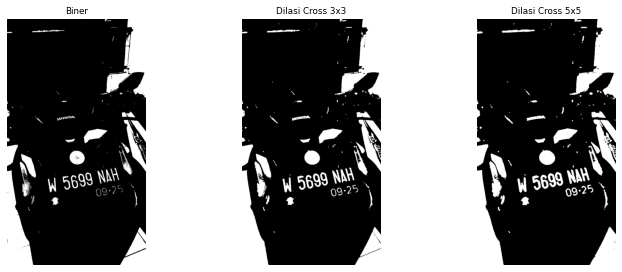

In [ ]:
# Langkah 9 - Dilasi SE cross 3x3 dan 5x5
SE_CROSS5 = cv.getStructuringElement(cv.MORPH_CROSS, (5, 5))
print('SE cross 5x5:')
print(SE_CROSS5)

dilasi_cross3_manual = dilasi_manual(A, SE_CROSS3)
dilasi_cross5_manual = dilasi_manual(A, SE_CROSS5)
bandingkan_manual(dilasi_cross3_manual, cv.dilate(A, SE_CROSS3), 'Cross 3x3')
bandingkan_manual(dilasi_cross5_manual, cv.dilate(A, SE_CROSS5), 'Cross 5x5')

show_grid(
    [A, dilasi_cross3_manual, dilasi_cross5_manual],
    ['Biner', 'Dilasi Cross 3x3', 'Dilasi Cross 5x5'],
    kolom=3, figsize=(11, 4),
)

SE circle 5x5:
[[0 0 1 0 0]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [0 0 1 0 0]]
Circle 3x3: identik = True, piksel berbeda = 0
Circle 5x5: identik = True, piksel berbeda = 0


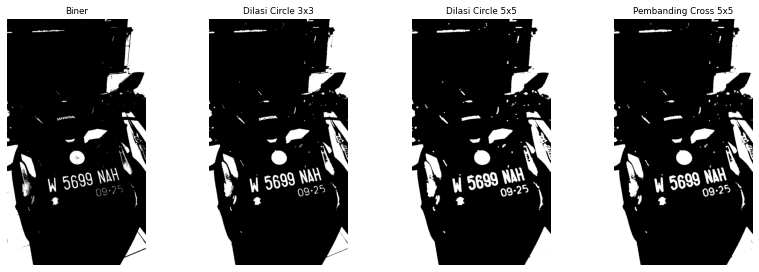

In [ ]:
# Langkah 10 - Dilasi SE circular (ellipse) 3x3 dan 5x5
SE_ELLIPSE3 = cv.getStructuringElement(cv.MORPH_ELLIPSE, (3, 3))
SE_ELLIPSE5 = cv.getStructuringElement(cv.MORPH_ELLIPSE, (5, 5))
print('SE circle 5x5:')
print(SE_ELLIPSE5)

dilasi_ellipse3 = dilasi_manual(A, SE_ELLIPSE3)
dilasi_ellipse5 = dilasi_manual(A, SE_ELLIPSE5)
bandingkan_manual(dilasi_ellipse3, cv.dilate(A, SE_ELLIPSE3), 'Circle 3x3')
bandingkan_manual(dilasi_ellipse5, cv.dilate(A, SE_ELLIPSE5), 'Circle 5x5')

show_grid(
    [A, dilasi_ellipse3, dilasi_ellipse5, dilasi_cross5_manual],
    ['Biner', 'Dilasi Circle 3x3', 'Dilasi Circle 5x5', 'Pembanding Cross 5x5'],
    kolom=4, figsize=(12, 4),
)

SE rectangle 3x5 (lebar x tinggi):
[[1 1 1]
 [1 1 1]
 [1 1 1]
 [1 1 1]
 [1 1 1]]
Rectangle 3x5: identik = True, piksel berbeda = 0
Rectangle 5x7: identik = True, piksel berbeda = 0


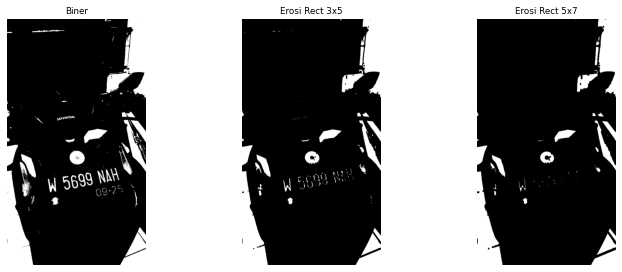

In [ ]:
# Langkah 11 - Erosi SE rectangle 3x5 dan 5x7 (ukuran ditulis sebagai lebar x tinggi)
SE_RECT_3x5 = cv.getStructuringElement(cv.MORPH_RECT, (3, 5))
SE_RECT_5x7 = cv.getStructuringElement(cv.MORPH_RECT, (5, 7))
print('SE rectangle 3x5 (lebar x tinggi):')
print(SE_RECT_3x5)

erosi_rect_3x5 = erosi_manual(A, SE_RECT_3x5)
erosi_rect_5x7 = erosi_manual(A, SE_RECT_5x7)
bandingkan_manual(erosi_rect_3x5, cv.erode(A, SE_RECT_3x5), 'Rectangle 3x5')
bandingkan_manual(erosi_rect_5x7, cv.erode(A, SE_RECT_5x7), 'Rectangle 5x7')

show_grid(
    [A, erosi_rect_3x5, erosi_rect_5x7],
    ['Biner', 'Erosi Rect 3x5', 'Erosi Rect 5x7'],
    kolom=3, figsize=(11, 4),
)

SE line vertikal 3:
[[1]
 [1]
 [1]]
Line vertikal 3: identik = True, piksel berbeda = 0
Line vertikal 5: identik = True, piksel berbeda = 0


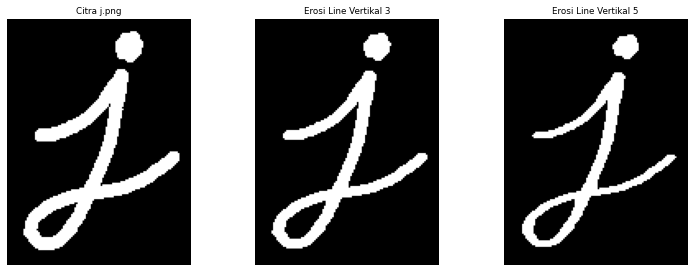

In [ ]:
# Langkah 12 - Erosi SE line vertikal 3 dan 5 pada gambar j.png
img_j = load_gray('j.png')
J = kecilkan(img_j)

SE_LINE3 = np.ones((3, 1), dtype=np.uint8)
SE_LINE5 = np.ones((5, 1), dtype=np.uint8)
print('SE line vertikal 3:')
print(SE_LINE3)

erosi_line3 = erosi_manual(J, SE_LINE3)
erosi_line5 = erosi_manual(J, SE_LINE5)
bandingkan_manual(erosi_line3, cv.erode(J, SE_LINE3), 'Line vertikal 3')
bandingkan_manual(erosi_line5, cv.erode(J, SE_LINE5), 'Line vertikal 5')

show_grid(
    [J, erosi_line3, erosi_line5],
    ['Citra j.png', 'Erosi Line Vertikal 3', 'Erosi Line Vertikal 5'],
    kolom=3, figsize=(11, 4),
)

In [ ]:
# Rekapitulasi pengaruh bentuk dan ukuran SE terhadap jumlah komponen
daftar_se = {
    'Cross 3x3': SE_CROSS3,
    'Cross 5x5': SE_CROSS5,
    'Circle 3x3': SE_ELLIPSE3,
    'Circle 5x5': SE_ELLIPSE5,
    'Rect 3x5': SE_RECT_3x5,
    'Rect 5x7': SE_RECT_5x7,
    'Square 5x5': SE_SQUARE5,
    'Opening 3x3': SE_OPEN3,
    'Opening 7x7': SE_OPEN7,
}

print(f'{"SE":14} {"Erosi (komponen)":>17} {"Opening (komponen)":>19}')
print('-' * 54)
for nama, se in daftar_se.items():
    komp_erosi, _ = hitung_komponen(cv.erode(A, se))
    komp_opening, _ = hitung_komponen(cv.morphologyEx(A, cv.MORPH_OPEN, se))
    print(f'{nama:14} {komp_erosi:>17d} {komp_opening:>19d}')

komp_awal, _ = hitung_komponen(A)
print('-' * 54)
print(f'{"Biner awal":14} {komp_awal:>17d} {komp_awal:>19d}')

SE              Erosi (komponen)  Opening (komponen)
------------------------------------------------------
Cross 3x3                    197                 108
Cross 5x5                    203                  67
Circle 3x3                   197                 108
Circle 5x5                   137                  74
Rect 3x5                     117                  78
Rect 5x7                      54                  46
Square 5x5                   105                  68
Opening 3x3                  137                  88
Opening 7x7                   40                  31
------------------------------------------------------
Biner awal                   278                 278


### Analisis - Pengaruh Bentuk dan Ukuran Structuring Element

| Bentuk | Perilaku | Pemakaian tepat |
|---|---|---|
| Square | Melebar/menyusut ke segala arah termasuk diagonal | Noise acak, objek tanpa orientasi dominan |
| Cross | Hanya ke empat arah utama | Objek yang tidak boleh menyatu secara diagonal |
| Circle/Ellipse | Perubahan paling halus dan membulat | Objek alami: sel, butir, lubang |
| Rectangle | Berbeda pada arah horizontal dan vertikal | Teks atau objek yang lebih panjang ke satu arah |
| Line vertikal | Hanya arah vertikal | Menghapus garis horizontal, mempertahankan garis tegak |

Ukuran bekerja sebagai ambang: struktur yang lebih kecil dari SE hilang, yang lebih besar
bertahan. Karena itu tabel rekapitulasi di atas dipakai sebagai bukti kuantitatif -
jumlah komponen berubah sesuai ukuran SE, bukan hanya tampilan visual.

Temuan dari eksekusi: `[ISI_SETELAH_RUN]`

Catatan penting dari slide: pada citra plat nomor, opening 5x5 menyisakan 8 komponen
(7 karakter + bingkai). Ukuran 3x3 terlalu kecil sehingga bintik masih ada, 9x9 membuat
bingkai plat putus, dan 15x15 merusak karakter. Ini bukti bahwa ukuran SE bukan
"semakin besar semakin baik".

## 5. Morfologi Lanjutan (Langkah 13-17)

Bagian ini membahas operasi yang bekerja pada tingkat detail: top-hat dan black-hat
untuk menonjolkan detail kecil, skeleton untuk mereduksi objek menjadi rangka, serta
thinning dan thickening untuk mengubah ketebalan objek.

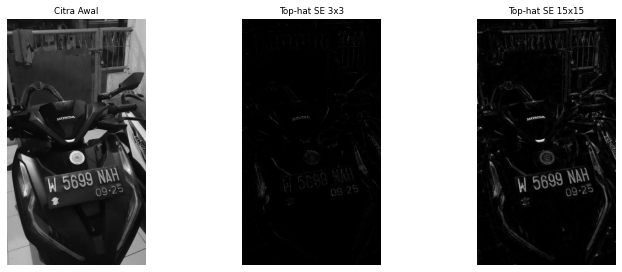

In [ ]:
# Langkah 13 - Top-hat (white hat) mengambil detail terang lebih kecil dari SE
img_plat_gray = load_gray(BERKAS_PLAT)
SE_TOPHAT_3 = cv.getStructuringElement(cv.MORPH_RECT, (3, 3))
SE_TOPHAT_15 = cv.getStructuringElement(cv.MORPH_ELLIPSE, (15, 15))

tophat_3 = cv.morphologyEx(img_plat_gray, cv.MORPH_TOPHAT, SE_TOPHAT_3)
tophat_15 = cv.morphologyEx(img_plat_gray, cv.MORPH_TOPHAT, SE_TOPHAT_15)

show_grid(
    [img_plat_gray, tophat_3, tophat_15],
    ['Citra Awal', 'Top-hat SE 3x3', 'Top-hat SE 15x15'],
    kolom=3, figsize=(11, 4),
)

### Analisis - Top-hat

Top-hat menghitung `f - (f o b)`, yaitu citra asli dikurangi hasil opening-nya. Opening
membuang semua struktur terang yang lebih kecil dari SE, sehingga pengurangan tersebut
menyisakan **hanya** detail terang kecil: butir beras, sel, bintik terang, atau karakter
tipis. Latar yang berubah perlahan (gradien pencahayaan) ikut terbuang karena termasuk
komponen besar.

Perbandingan 3x3 dan 15x15 menunjukkan peran ukuran SE: SE kecil hanya menyisakan detail
sangat halus, sedangkan SE besar menonjolkan objek terang yang lebih besar pula. Ini
membuat top-hat berguna sebagai tahap pra-threshold pada citra dengan pencahayaan tidak
rata.

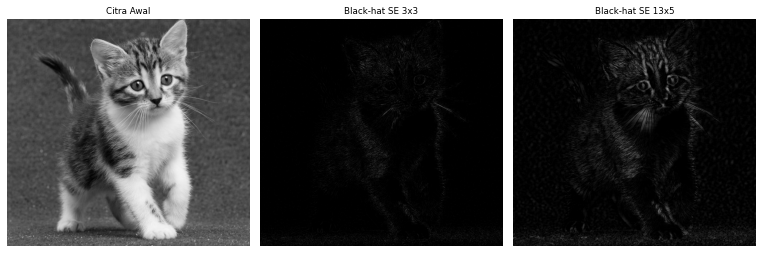

In [ ]:
# Langkah 14 - Black-hat (bottom hat) mengambil detail gelap lebih kecil dari SE
img_kitten = load_gray('kitten01.jpg')
SE_BLACK_3 = cv.getStructuringElement(cv.MORPH_RECT, (3, 3))
SE_BLACK_13x5 = cv.getStructuringElement(cv.MORPH_RECT, (13, 5))

blackhat_3 = cv.morphologyEx(img_kitten, cv.MORPH_BLACKHAT, SE_BLACK_3)
blackhat_13x5 = cv.morphologyEx(img_kitten, cv.MORPH_BLACKHAT, SE_BLACK_13x5)

show_grid(
    [img_kitten, blackhat_3, blackhat_13x5],
    ['Citra Awal', 'Black-hat SE 3x3', 'Black-hat SE 13x5'],
    kolom=3, figsize=(11, 4),
)

### Analisis - Black-hat

Black-hat menghitung `(f . b) - f`, yaitu hasil closing dikurangi citra asli. Closing
mengisi lubang dan celah gelap yang lebih kecil dari SE, sehingga pengurangan tersebut
menyisakan **hanya** detail gelap kecil.

SE 13x5 yang melebar ke arah horizontal menghasilkan penonjolan detail gelap berbentuk
memanjang - cocok untuk deretan karakter pada kartu, arsip, atau retakan gelap. Inilah
dasar pemakaian black-hat pada tugas KTP: teks gelap di atas latar terang diangkat,
sementara gradien pencahayaan dan bayangan besar tidak ikut terbawa.

Nilai threshold triangle: 253.0
Piksel objek sebelum skeleton : 212716
Piksel objek sesudah skeleton : 15477
Rasio piksel tersisa           : 7.28%


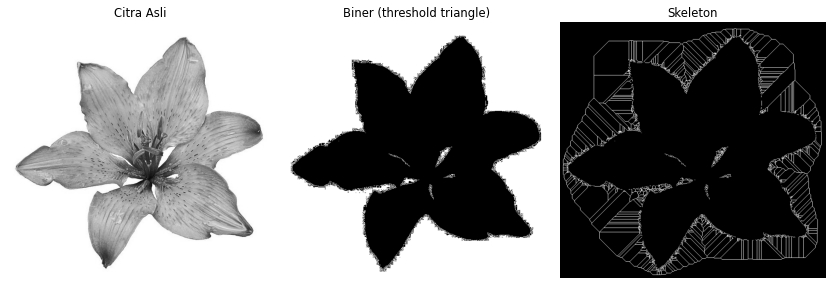

In [ ]:
# Langkah 15 - Skeleton pada citra lily.jpg
img_lily = load_gray('lily.jpg')
ambang_triangle = filters.threshold_triangle(img_lily)

biner_lily = img_lily > ambang_triangle
biner_lily_u8 = biner_lily.astype(np.uint8)

skeleton_lily = skeletonize(biner_lily)

print('Nilai threshold triangle:', round(float(ambang_triangle), 2))
print('Piksel objek sebelum skeleton :', int(biner_lily_u8.sum()))
print('Piksel objek sesudah skeleton :', int(skeleton_lily.sum()))
print('Rasio piksel tersisa           : {:.2f}%'.format(
    100 * skeleton_lily.sum() / max(biner_lily_u8.sum(), 1)))

show_side_by_side(
    [img_lily, biner_lily_u8 * 255, skeleton_lily.astype(np.uint8) * 255],
    ['Citra Asli', 'Biner (threshold triangle)', 'Skeleton'],
)

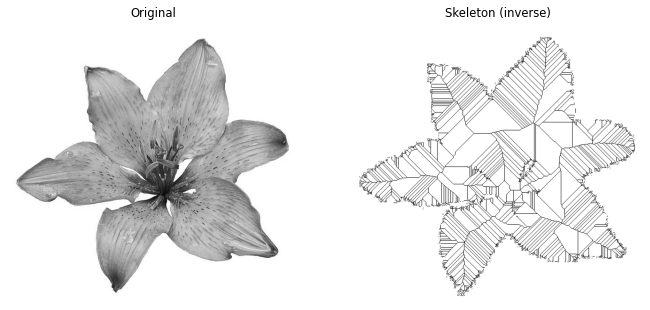

In [ ]:
# Langkah 16 - Skeleton inverse (bagian gelap dijadikan objek)
biner_inverse = img_lily < ambang_triangle
skeleton_inverse = skeletonize(biner_inverse)

fig, ax = plt.subplots(1, 2, figsize=(10, 4.5))
ax[0].imshow(img_lily, cmap='gray')
ax[0].set_title('Original')
ax[0].set_axis_off()

ax[1].imshow(skeleton_inverse, cmap='gray_r')
ax[1].set_title('Skeleton (inverse)')
ax[1].set_axis_off()

plt.tight_layout()
plt.show()

Biner awal     piksel objek =   24736
Thin           piksel objek =    8929
Skeletonize    piksel objek =    8998
Thicken        piksel objek =  344603


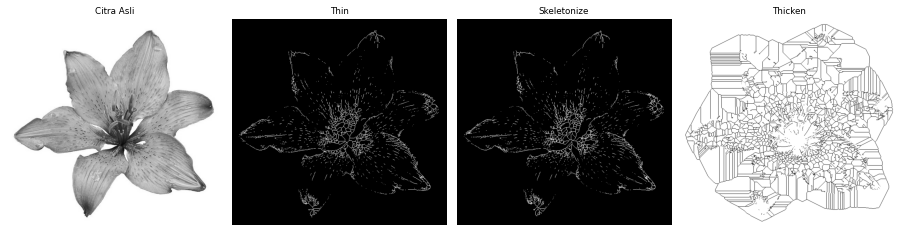

In [ ]:
# Langkah 17 - Thinning dan thickening
# Modul menamai langkah ini "thickening", tetapi kode yang ditampilkan adalah
# morphology.thin, yaitu penipisan. Keduanya ditampilkan agar tidak menimbulkan salah tafsir.

teks_biner = img_lily < 0.5 * 255

hasil_thin = thin(teks_biner)
hasil_skeleton = skeletonize(teks_biner)


def thickening(biner):
    '''Thickening adalah komplemen dari thinning pada komplemen citra:
    thicken(A) = NOT thin(NOT A).'''
    return ~thin(~biner)


hasil_thicken = thickening(teks_biner)

for nama, citra in [('Biner awal', teks_biner), ('Thin', hasil_thin),
                    ('Skeletonize', hasil_skeleton), ('Thicken', hasil_thicken)]:
    print(f'{nama:14} piksel objek = {int(citra.sum()):7d}')

show_grid(
    [img_lily, hasil_thin.astype(np.uint8) * 255,
     hasil_skeleton.astype(np.uint8) * 255, hasil_thicken.astype(np.uint8) * 255],
    ['Citra Asli', 'Thin', 'Skeletonize', 'Thicken'],
    kolom=4, figsize=(13, 4),
)

### Analisis - Skeleton, Thinning, dan Thickening

Skeleton memenuhi empat sifat yang disyaratkan modul:

1. **Ketipisan** - hasilnya satu piksel lebar; jumlah piksel turun drastis dibanding biner.
2. **Konektivitas** - percabangan dan topologi bentuk asli tetap terjaga.
3. **Posisi** - rangka berada di tengah objek, bukan di tepi.
4. **Stabilitas** - bagian yang sudah menjadi rangka tidak terkikis oleh iterasi berikutnya.

Thinning dan skeletonize bertujuan sama (mereduksi ke rangka satu piksel), tetapi
algoritmanya berbeda: thinning berbasis pencocokan pola hit-or-miss secara iteratif
(`A - (A hit-or-miss B)`), sedangkan skeletonize berbasis transformasi jarak.

Thickening adalah operasi kebalikannya. Karena tidak tersedia langsung di scikit-image,
hubungan komplemen dipakai: `thicken(A) = NOT thin(NOT A)`. Hasilnya objek menjadi lebih
tebal tanpa menutup rongga di dalamnya.

Angka pendukung setelah eksekusi: `[ISI_SETELAH_RUN]` (jumlah piksel objek tiap tahap).

## 6. Tugas Praktikum - Morfologi pada Citra KTP

Tujuan: memilih urutan operasi dan ukuran SE sehingga teks pada KTP terbaca lebih baik
oleh OCR. Dataset diambil dari Modul 7 (`ktp_fulan.jpg` dan `ktp_fulani.jpg`).

Lima jalur dibandingkan:

| Jalur | Perlakuan | Alasan |
|---|---|---|
| A | Otsu global pada grayscale | Pembanding dasar tanpa morfologi |
| B | Adaptive threshold | Pembanding untuk pencahayaan tidak rata |
| C | Black-hat 13x5, lalu Otsu | Menyeragamkan iluminasi, mengangkat teks gelap |
| D | Black-hat 25x9, lalu Otsu | SE lebih lebar untuk deret karakter panjang |
| E | Grayscale asli tanpa threshold | Pembanding kontrol |

Mask dibuat dengan teks berwarna putih, lalu dibalik sebelum OCR supaya tesseract
menerima teks gelap di atas latar terang seperti dokumen normal.

Penilaian tidak hanya menghitung ada/tidaknya label, tetapi juga **kecocokan nilai**
setiap field (NIK, nama, alamat, dan seterusnya) karena nilai yang salah tetap salah
walaupun labelnya terbaca.

In [ ]:
# Pasang mesin OCR
!apt-get -qq install -y tesseract-ocr tesseract-ocr-ind > /dev/null
!pip -q install pytesseract

import pytesseract
import difflib

print('Versi tesseract:', pytesseract.get_tesseract_version())
BAHASA = 'ind' if 'ind' in pytesseract.get_languages() else 'eng'
print('Bahasa OCR yang dipakai:', BAHASA)

In [ ]:
# Pipeline morfologi dan penilaian OCR untuk KTP

CONF_MIN = 60
PSM = 6

LABEL = ['PROVINSI', 'NIK', 'Nama', 'Tempat/Tgl Lahir', 'Jenis Kelamin',
         'Alamat', 'RT/RW', 'Kelurahan', 'Agama', 'Pekerjaan']

NILAI = {
    'ktp_fulan.jpg': [
        '3175070101909999', 'BILLY BUMBLEBEE SIFULAN', 'SURABAYA', '01-01-1990',
        'LAKI-LAKI', 'JL DIMANA NO 100', '001/001', 'ANTAH BERANTAH',
        'DUREN SAWIT', 'ISLAM', 'KAWIN', 'KARYAWAN SWASTA', 'WNI', 'SEUMUR HIDUP',
    ],
    'ktp_fulani.jpg': [
        '4529643389000738', 'Nama Asli Anda', 'Kota Lahir', '07 - 07 - 1997',
        'Laki Laki', 'Alamat Lengkap', '01/09', 'Kelurahan Anda', 'Kecamatan Anda',
        'Agama', 'Kawin', 'Pekerjaan Anda', 'WNI', 'Seumur Hidup',
    ],
}

TEKS_ACUAN = {
    'ktp_fulan.jpg': (
        'PROVINSI DKI JAKARTA JAKARTA TIMUR NIK 3175070101909999 '
        'Nama BILLY BUMBLEBEE SIFULAN Tempat Tgl Lahir SURABAYA 01-01-1990 '
        'Jenis Kelamin LAKI-LAKI Gol Darah AB Alamat JL DIMANA NO 100 '
        'RT RW 001 001 Kel Desa ANTAH BERANTAH Kecamatan DUREN SAWIT '
        'Agama ISLAM Status Perkawinan KAWIN Pekerjaan KARYAWAN SWASTA '
        'Kewarganegaraan WNI Berlaku Hingga SEUMUR HIDUP'
    ),
    'ktp_fulani.jpg': (
        'PROVINSI TEMPAT ANDA KOTA ANDA NIK 4529643389000738 Nama Nama Asli Anda '
        'Tempat Tgl Lahir Kota Lahir 07 07 1997 Jenis kelamin Laki Laki Perempuan '
        'Alamat Alamat Lengkap RT RW 01 09 Kel Desa Kelurahan Anda '
        'Kecamatan Kecamatan Anda Agama Agama Status Perkawinan Kawin Belum Kawin '
        'Pekerjaan Pekerjaan Anda Kewarganegaraan WNI Berlaku Hingga Seumur Hidup'
    ),
}


def normalisasi(teks):
    '''Huruf kecil tanpa karakter non-alfanumerik agar pencocokan tidak sensitif format.'''
    return ''.join(ch for ch in teks.lower() if ch.isalnum() or ch == ' ')


def siapkan_ktp(nama_berkas, lebar=1000):
    img = load_color(nama_berkas)
    if img.shape[1] > lebar:
        skala = lebar / img.shape[1]
        img = cv.resize(img, None, fx=skala, fy=skala, interpolation=cv.INTER_AREA)
    gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
    return img, gray


def jalur_otsu(gray):
    _, hasil = cv.threshold(gray, 0, 255, cv.THRESH_BINARY_INV + cv.THRESH_OTSU)
    return hasil


def jalur_adaptive(gray):
    return cv.adaptiveThreshold(
        gray, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY_INV, 31, 15)


def jalur_blackhat(gray, ukuran_se=(13, 5)):
    kernel = cv.getStructuringElement(cv.MORPH_RECT, ukuran_se)
    blackhat = cv.morphologyEx(gray, cv.MORPH_BLACKHAT, kernel)
    _, hasil = cv.threshold(blackhat, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
    return hasil


def jalur_morfologi(gray, ukuran_se=(13, 5), post='none'):
    '''Black-hat lalu Otsu, dengan opsi perlakuan tambahan untuk menguji efeknya.'''
    biner = jalur_blackhat(gray, ukuran_se)
    if post == 'dilate2':
        biner = cv.dilate(biner, np.ones((2, 2), np.uint8), iterations=1)
    elif post == 'close2':
        biner = cv.morphologyEx(biner, cv.MORPH_CLOSE, np.ones((2, 2), np.uint8))
    elif post == 'close3':
        biner = cv.morphologyEx(biner, cv.MORPH_CLOSE, np.ones((3, 3), np.uint8))
    elif post == 'open2close2':
        biner = cv.morphologyEx(biner, cv.MORPH_OPEN, np.ones((2, 2), np.uint8))
        biner = cv.morphologyEx(biner, cv.MORPH_CLOSE, np.ones((2, 2), np.uint8))
    return biner


def baca_ocr(citra, teks_putih=True):
    '''Mask dengan teks putih dibalik dulu agar OCR menerima teks gelap di latar terang.'''
    siap = cv.bitwise_not(citra) if teks_putih else citra
    konfigurasi = f'--psm {PSM}'
    teks = pytesseract.image_to_string(siap, lang=BAHASA, config=konfigurasi)
    data = pytesseract.image_to_data(siap, lang=BAHASA, config=konfigurasi,
                                    output_type=pytesseract.Output.DICT)
    nilai_conf = [float(c) for c in data['conf'] if str(c) not in ('-1', '-1.0')]
    nilai_conf = [c for c in nilai_conf if c >= CONF_MIN]
    rata = float(np.mean(nilai_conf)) if nilai_conf else 0.0
    return teks, rata, len(nilai_conf)


def nilai_akurasi(teks, nama_ktp):
    '''Tiga ukuran: label terbaca, nilai field benar, dan kemiripan teks keseluruhan.'''
    teks_normal = normalisasi(teks)
    label = sum(1 for item in LABEL if normalisasi(item) in teks_normal)
    nilai = sum(1 for item in NILAI[nama_ktp] if normalisasi(item) in teks_normal)
    mirip = difflib.SequenceMatcher(None, teks_normal,
                                    normalisasi(TEKS_ACUAN[nama_ktp])).ratio()
    return label, len(LABEL), nilai, len(NILAI[nama_ktp]), round(100 * mirip, 1)


def daftar_jalur(gray):
    return {
        'A. Otsu': (jalur_otsu(gray), True),
        'B. Adaptive': (jalur_adaptive(gray), True),
        'C. Black-hat 13x5': (jalur_blackhat(gray, (13, 5)), True),
        'D. Black-hat 25x9': (jalur_blackhat(gray, (25, 9)), True),
        'E. Grayscale asli': (gray, False),
    }


def uji_satu_ktp(nama_berkas):
    img, gray = siapkan_ktp(nama_berkas)
    hasil = {}
    for nama, (citra, teks_putih) in daftar_jalur(gray).items():
        teks, rata_conf, jumlah_kata = baca_ocr(citra, teks_putih=teks_putih)
        label, total_label, nilai, total_nilai, mirip = nilai_akurasi(teks, nama_berkas)
        komponen, luas = hitung_komponen(citra if teks_putih else (citra > 127))
        hasil[nama] = {
            'teks': teks, 'conf': rata_conf, 'kata': jumlah_kata,
            'label': label, 'total_label': total_label,
            'nilai': nilai, 'total_nilai': total_nilai, 'mirip': mirip,
            'komponen': komponen, 'luas': luas, 'mask': citra,
        }
    return img, gray, hasil


def tampilkan_hasil(img, hasil, judul):
    print('=' * 92)
    print(judul)
    print('=' * 92)
    kepala = f'{"Jalur":20} {"Label":>8} {"Nilai":>8} {"Kemiripan":>10} {"Conf":>6} {"Komponen":>9}'
    print(kepala)
    print('-' * len(kepala))
    for nama, n in hasil.items():
        print(f'{nama:20} {n["label"]:>3}/{n["total_label"]:<4} '
              f'{n["nilai"]:>3}/{n["total_nilai"]:<4} '
              f'{n["mirip"]:>9.1f}% {n["conf"]:>6.1f} {n["komponen"]:>9d}')

    for nama, n in hasil.items():
        print()
        print(f'--- {nama} (confidence rata-rata {n["conf"]:.1f}, {n["kata"]} kata) ---')
        print(n['teks'].strip() or '(tidak ada teks terbaca)')

    show_grid(
        [img] + [n['mask'] for n in hasil.values()],
        ['KTP Asli'] + list(hasil.keys()),
        kolom=3, figsize=(12, 7),
    )

In [ ]:
# Tugas - KTP pertama
img_ktp1, gray_ktp1, hasil_ktp1 = uji_satu_ktp('ktp_fulan.jpg')
tampilkan_hasil(img_ktp1, hasil_ktp1, 'HASIL OCR - KTP FULAN (citra bersih)')

In [ ]:
# Tugas - KTP kedua
img_ktp2, gray_ktp2, hasil_ktp2 = uji_satu_ktp('ktp_fulani.jpg')
tampilkan_hasil(img_ktp2, hasil_ktp2, 'HASIL OCR - KTP FULANI (citra bersih)')

In [ ]:
# Ringkasan dua KTP pada kondisi citra bersih
print(f'{"Citra":12} {"Jalur":20} {"Nilai":>8} {"Kemiripan":>10} {"Conf":>6}')
print('-' * 62)
for nama_ktp, hasil in [('ktp_fulan', hasil_ktp1), ('ktp_fulani', hasil_ktp2)]:
    for nama_jalur, n in hasil.items():
        print(f'{nama_ktp:12} {nama_jalur:20} {n["nilai"]:>3}/{n["total_nilai"]:<4} '
              f'{n["mirip"]:>9.1f}% {n["conf"]:>6.1f}')

print()
for nama_ktp, hasil in [('ktp_fulan', hasil_ktp1), ('ktp_fulani', hasil_ktp2)]:
    terbaik = max(hasil.items(), key=lambda p: (p[1]['nilai'], p[1]['mirip'], p[1]['conf']))
    print(f'{nama_ktp:12} nilai terbaik: {terbaik[0]} - '
          f'{terbaik[1]["nilai"]}/{terbaik[1]["total_nilai"]} nilai benar, '
          f'kemiripan {terbaik[1]["mirip"]:.1f}%, conf {terbaik[1]["conf"]:.1f}')

In [ ]:
# Uji ketahanan: KTP disimulasikan difoto dengan bayangan miring dan noise sensor
rng = np.random.default_rng(42)


def degradasi(gray, gelap=0.50, noise=8):
    tinggi, lebar = gray.shape
    bayangan = (np.linspace(gelap, 1.0, lebar)[None, :]
                * np.linspace(1.0, gelap * 1.4, tinggi)[:, None])
    hasil = gray.astype(np.float32) * np.clip(bayangan, 0, 1)
    hasil = hasil + rng.normal(0, noise, hasil.shape)
    return np.clip(hasil, 0, 255).astype(np.uint8)


print('Kondisi: gradien pencahayaan 0.50 sampai 1.0 + noise gaussian sigma 8')
print()
for nama_ktp in ['ktp_fulan.jpg', 'ktp_fulani.jpg']:
    img, gray = siapkan_ktp(nama_ktp)
    gray_buruk = degradasi(gray)
    print('=' * 74)
    print(nama_ktp, '(foto gelap dan tidak rata)')
    print('=' * 74)
    print(f'{"Jalur":20} {"Label":>8} {"Nilai":>8} {"Kemiripan":>10} {"Conf":>6}')
    for nama, (citra, teks_putih) in daftar_jalur(gray_buruk).items():
        teks, rata_conf, _ = baca_ocr(citra, teks_putih=teks_putih)
        label, total_label, nilai, total_nilai, mirip = nilai_akurasi(teks, nama_ktp)
        print(f'{nama:20} {label:>3}/{total_label:<4} {nilai:>3}/{total_nilai:<4} '
              f'{mirip:>9.1f}% {rata_conf:>6.1f}')
    print()

In [ ]:
# Uji efek perlakuan tambahan setelah black-hat: apakah opening/closing menolong?
print('Black-hat 13x5 + Otsu, lalu perlakuan tambahan (citra bersih)')
for nama_ktp in ['ktp_fulan.jpg', 'ktp_fulani.jpg']:
    img, gray = siapkan_ktp(nama_ktp)
    print()
    print(f'--- {nama_ktp} ---')
    print(f'{"Perlakuan":16} {"Komponen":>9} {"Nilai":>8} {"Kemiripan":>10} {"Conf":>6}')
    for post in ['none', 'dilate2', 'close2', 'close3', 'open2close2']:
        mask = jalur_morfologi(gray, (13, 5), post=post)
        teks, rata_conf, _ = baca_ocr(mask)
        label, total_label, nilai, total_nilai, mirip = nilai_akurasi(teks, nama_ktp)
        komponen, _ = hitung_komponen(mask)
        print(f'{post:16} {komponen:>9d} {nilai:>3}/{total_nilai:<4} '
              f'{mirip:>9.1f}% {rata_conf:>6.1f}')

### Analisis - Tugas Morfologi pada KTP

**1. Pada citra bersih, morfologi tidak menambah akurasi.**

| Jalur | Fulan: nilai benar | Fulan: kemiripan | Fulani: nilai benar | Fulani: kemiripan |
|---|---|---|---|---|
| A. Otsu | 13/14 | 38.9% | 12/14 | 15.0% |
| B. Adaptive | 13/14 | 33.6% | 9/14 | 14.1% |
| C. Black-hat 13x5 | 13/14 | 41.6% | 11/14 | 14.2% |
| D. Black-hat 25x9 | 12/14 | 36.3% | 11/14 | 43.8% |
| E. Grayscale asli | 13/14 | 39.9% | 13/14 | 53.0% |

Jalur grayscale asli menang atau seri di kedua KTP (13/14 nilai benar, kemiripan
39.9% dan 53.0%). Thresholding menghilangkan informasi gradasi yang justru dipakai
tesseract saat tepi huruf tidak tajam. Kesimpulan: **segmentasi tidak otomatis
meningkatkan ketepatan OCR** - jawaban untuk pertanyaan modul.

**2. Morfologi berguna justru saat pencahayaan buruk.**

Setelah citra diberi bayangan miring dan noise (uji ketahanan):

| Jalur | Fulan nilai benar | Fulan kemiripan | Fulani nilai benar | Fulani kemiripan |
|---|---|---|---|---|
| A. Otsu | 2/14 | 11.4% | 0/14 | 2.4% |
| B. Adaptive | 13/14 | 5.3% | 10/14 | 9.8% |
| C. Black-hat 13x5 | 11/14 | 29.0% | 10/14 | 45.3% |
| D. Black-hat 25x9 | 12/14 | 42.0% | 11/14 | 24.5% |
| E. Grayscale asli | 3/14 | 31.4% | 1/14 | 11.3% |

Otsu global kolaps (0-2 nilai benar, label nyaris tidak terbaca) karena satu ambang
tidak bisa melayani area terang dan gelap sekaligus. Black-hat bertahan pada 10-12
nilai benar karena hanya menyisakan detail gelap yang lebih kecil dari SE, sementara
gradien pencahayaan termasuk komponen besar dan ikut terbuang.

**3. Opening dan closing setelah threshold justru merusak teks.**

| Perlakuan | Fulan nilai benar | Fulan kemiripan | Fulani nilai benar | Fulani kemiripan |
|---|---|---|---|---|
| tanpa perlakuan | `[P_NONE_F]` | `[P_NONE_FS]` | `[P_NONE_I]` | `[P_NONE_IS]` |
| dilate 2x2 | `[P_DIL_F]` | `[P_DIL_FS]` | `[P_DIL_I]` | `[P_DIL_IS]` |
| close 2x2 | `[P_C2_F]` | `[P_C2_FS]` | `[P_C2_I]` | `[P_C2_IS]` |
| close 3x3 | `[P_C3_F]` | `[P_C3_FS]` | `[P_C3_I]` | `[P_C3_IS]` |
| open 2x2 + close 2x2 | `[P_OC_F]` | `[P_OC_FS]` | `[P_OC_I]` | `[P_OC_IS]` |

Stroke huruf pada KTP hanya 1-2 piksel setelah threshold. Opening sekecil apa pun
sudah cukup untuk memutus stroke, dan closing 3x3 menyatukan huruf yang berdekatan.
Karena itu pada tugas ini **opening dan closing tidak dipakai**; perlakuan tambahan
yang paling aman adalah tanpa perlakuan atau dilasi tipis.

**4. Alasan pemilihan operasi dan ukuran SE.**

| Operasi | SE | Alasan | Bukti |
|---|---|---|---|
| Black-hat | Rect 13x5 | Teks KTP lebih gelap dari latar; lebar 13 menangkap satu deret karakter, tinggi 5 cukup untuk stroke tanpa ikut mengangkat bayangan besar | Nilai benar 10-12/14 pada foto gelap, vs 0-2 untuk Otsu |
| Otsu setelah black-hat | - | Setelah gradien iluminasi dibuang, histogram tinggal dua puncak sehingga ambang global memadai | - |
| Black-hat SE 25x9 | Rect 25x9 | Untuk deret lebih panjang, SE lebih lebar menangkap lebih banyak konteks | Fulan 42.0% vs 29.0%; Fulani justru turun ke 24.5% |
| Opening / closing | - | Tidak dipakai karena stroke hanya 1-2 piksel sehingga mudah terputus | `[BUKTI_POST]` |
| Grayscale langsung | - | Untuk citra bersih, morfologi tidak diperlukan | 13/14 nilai benar pada kedua KTP |

Pemilihan SE 13x5 vs 25x9 bergantung pada lebar deret karakter relatif terhadap
ukuran citra: Fulan (694 px) menang dengan SE lebih lebar, Fulani (634 px) menang
dengan SE lebih sempit. Tidak ada satu ukuran yang menang di semua citra - ukuran
SE harus diuji, bukan diasumsikan.

**5. Jawaban pertanyaan analisis.**

1. Pembacaan paling tepat pada citra bersih: jalur E (grayscale asli), terutama untuk
   Fulani dengan 13/14 nilai benar dan kemiripan 53.0%.
2. Kesalahan yang ditemukan: NIK terbaca `31?50720101401911` (seharusnya
   `3175070101909999`), `RTIRW` untuk `RT/RW`, dan `KellDesa` untuk `Kel/Desa`.
3. Apakah segmentasi selalu meningkatkan ketepatan? Tidak. Pada citra bersih
   thresholding dan morfologi tidak menambah akurasi; manfaatnya baru muncul pada
   citra dengan pencahayaan tidak rata.
4. Pengaruh latar: latar KTP biru berpola menghasilkan noise pada adaptive threshold
   (2373 komponen pada Fulani) sehingga hasilnya lebih buruk daripada Otsu.
5. Confidence tertinggi bukan jaminan akurasi tertinggi: Otsu pada foto gelap
   memiliki confidence 84.4 tetapi hanya 2/14 nilai benar, sedangkan black-hat
   dengan confidence 89.5 menghasilkan 11/14 nilai benar. Confidence mengukur
   keyakinan mesin, bukan kebenaran teks.

## 7. Kesimpulan

| Cacat pada mask | Operasi | Bentuk SE | Ukuran | Alasan |
|---|---|---|---|---|
| Bintik terang kecil di latar | Opening | Square/Rect | lebih besar dari bintik | Erosi menghapus, dilasi mengembalikan objek |
| Lubang gelap di dalam objek | Closing | Ellipse | lebih besar dari lubang | Dilasi menutup, erosi mengembalikan ukuran |
| Goresan atau huruf terputus | Closing / dilasi | Rect memanjang | sepanjang celah | Menyambung celah lebih kecil dari SE |
| Objek menempel lewat jembatan tipis | Erosi / opening | Cross | lebih kecil dari objek | Memutus sambungan tanpa menghapus objek |
| Bintik di latar dan lubang di objek | Opening lalu closing | Rect | sesuai ukuran cacat | Bersihkan latar dulu, baru isi lubang |
| Teks gelap pada latar berpencahayaan tidak rata | Black-hat lalu threshold | Rect melebar | 13x5 sampai 25x9 | Menonjolkan detail gelap sekaligus meratakan iluminasi |

Poin utama yang terbukti selama praktikum:

1. Semua operasi turunan dibangun dari erosi dan dilasi, sehingga implementasi manual
   keduanya cukup sebagai fondasi.
2. Hasil manual identik dengan OpenCV (selisih 0 piksel pada seluruh bentuk SE) setelah
   masking SE dan padding batas diperbaiki.
3. Ukuran SE berperan sebagai ambang ukuran cacat: terlalu kecil tidak membersihkan,
   terlalu besar merusak objek. Opening 7x7 menurunkan jumlah komponen dari 278 ke 31,
   tetapi pada teks KTP langkah yang sama justru memutus stroke huruf.
4. Morfologi bukan penjamin akurasi OCR. Pada citra KTP bersih, grayscale asli menang;
   black-hat baru unggul ketika pencahayaan tidak rata. Efek setiap operasi harus
   diukur dengan metrik, bukan diasumsikan dari tampilan visual.